## AmesHousing
#### Schritt 1: Initialisierung und Laden
Importieren Sie die erforderlichen Data-Science-Bibliotheken und laden Sie den tabulatorgetrennten Datensatz in einen pandas-DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_dataset = pd.read_csv("AmesHousing.csv", sep='\t')

display(train_dataset.head())

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


#### Schritt 2: Datenprüfung
Überprüfen Sie die Datentypen, die Zeilenanzahl und die Zusammenfassungsstatistiken (Minimum, Maximum, Perzentile), um sich einen Überblick über den Umfang des Datensatzes zu verschaffen.

In [2]:
train_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

In [3]:
display(train_dataset.describe())

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


#### Schritt 3: Umgang mit fehlenden Werten
Spalten mit fehlenden Daten werden identifiziert. Spalten, die fast vollständig leer sind (wie „Pool QC“ oder „Fence“), werden verworfen, da sie eine Varianz nahe Null aufweisen. Die verbleibenden fehlenden Werte werden imputiert (bei Textdaten mit „Keine“ und bei Zahlen mit 0 ergänzt).

In [4]:
missing_values = train_dataset.isna().sum()

print(missing_values[missing_values > 0].sort_values(ascending=False))

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
BsmtFin SF 1         1
BsmtFin SF 2         1
Electrical           1
Total Bsmt SF        1
Bsmt Unf SF          1
Garage Area          1
Garage Cars          1
dtype: int64


In [5]:
train_dataset = train_dataset.drop(columns=["Pool QC"])
train_dataset = train_dataset.drop(columns=["Misc Feature"])
train_dataset = train_dataset.drop(columns=["Alley"])
train_dataset = train_dataset.drop(columns=["Fence"])

In [6]:
categorical_cols = train_dataset.select_dtypes(include=['object', 'str']).columns
train_dataset[categorical_cols] = train_dataset[categorical_cols].fillna("None")

numerical_cols = train_dataset.select_dtypes(include=['int64', 'float64']).columns
train_dataset[numerical_cols] = train_dataset[numerical_cols].fillna(0)

print("Gesamtzahl der verbleibenden fehlenden Werte:",  train_dataset.isna().sum().sum())

Gesamtzahl der verbleibenden fehlenden Werte: 0


## Explorative Visualisierungen

#### Histogramm
Ein Histogramm mit einer KDE-Kurve wurde erstellt, um die Häufigkeitsverteilung einer einzelnen numerischen Variable zu visualisieren. Dies zeigt auf einen Blick, wo sich die meisten Datenpunkte häufen und ob die Verteilung Schiefen aufweist.

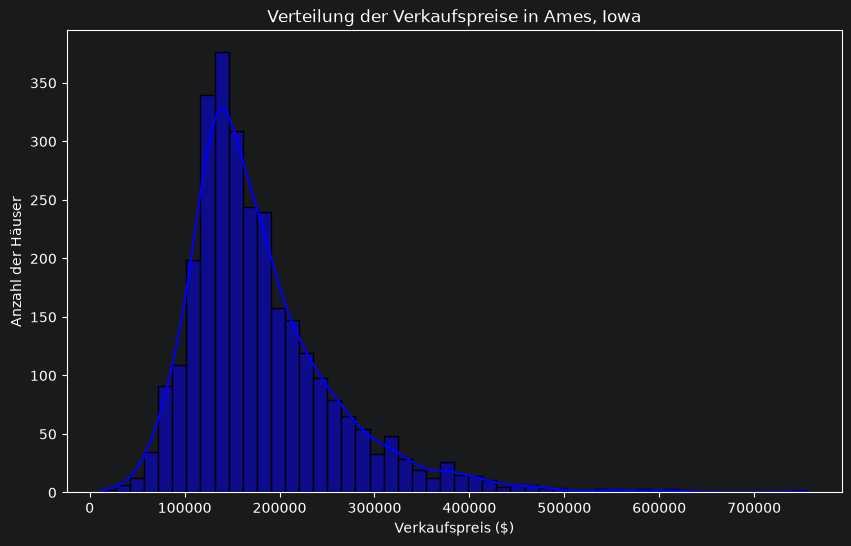

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(train_dataset['SalePrice'], kde=True, bins=50, color='blue')
plt.title('Verteilung der Verkaufspreise in Ames, Iowa')
plt.xlabel('Verkaufspreis ($)')
plt.ylabel('Anzahl der Häuser')
plt.show()

Die Verteilung der Verkaufspreise im Ames-Datensatz ist stark rechtsschief. Die überwiegende Mehrheit der Häuser wird in der Spanne von 100.000 bis 200.000 Dollar verkauft, wobei sich die höchste Konzentration (der Höhepunkt der Verteilung) um 150.000 bis 160.000 Dollar konzentriert. Ein langer rechter Schwanz deutet auf eine kleine Untergruppe von Luxusimmobilien hin, die für 300.000 bis über 500.000 Dollar verkauft werden, was den Durchschnittspreis (Mittelwert) deutlich über den Medianpreis zieht.

#### Boxplot
Es wurde ein Boxplot generiert, um die Verteilung einer numerischen Variable über verschiedene Kategorien hinweg zu vergleichen. Dadurch lassen sich der Median, die Streuung der mittleren 50 Prozent der Daten (Quartile) sowie mögliche Ausreißer in den jeweiligen Gruppen direkt ablesen.

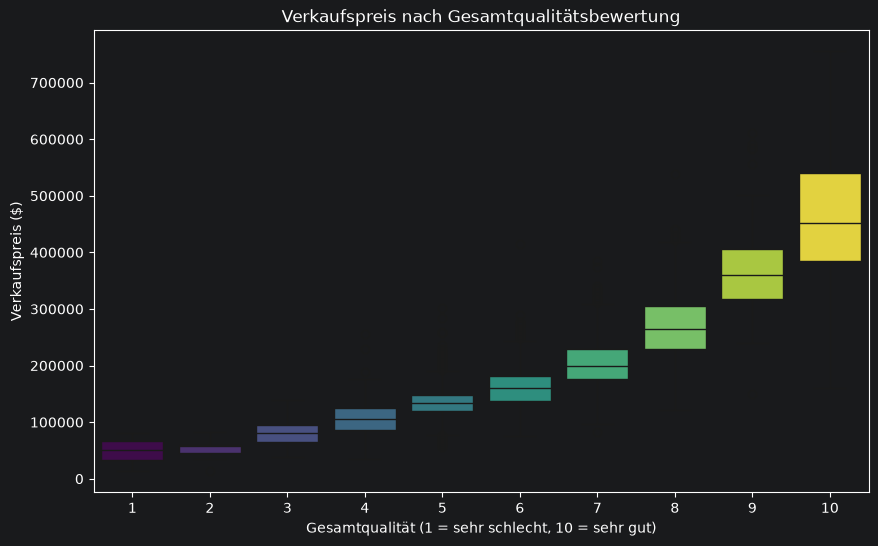

In [8]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    x='Overall Qual',
    y='SalePrice',
    data=train_dataset,
    palette='viridis',
    hue='Overall Qual',
    legend=False
)
plt.title('Verkaufspreis nach Gesamtqualitätsbewertung')
plt.xlabel('Gesamtqualität (1 = sehr schlecht, 10 = sehr gut)')
plt.ylabel('Verkaufspreis ($)')
plt.show()

Es besteht ein eindeutiger, positiver und nichtlinearer (nahezu exponentieller) Zusammenhang zwischen der Gesamtqualitätsbewertung (1–10) und dem Verkaufspreis. Mit steigender Qualitätsbewertung steigt der Medianverkaufspreis deutlich an. Die Streuung der Daten (die Größe der Boxen) nimmt bei Immobilien höherer Qualität (Bewertungen 8, 9 und 10) ebenfalls erheblich zu, was darauf hindeutet, dass die Preise für Luxusimmobilien wesentlich stärker schwanken und stark von zusätzlichen Faktoren wie Größe oder Lage abhängen. Darüber hinaus gibt es mehrere hochpreisige Ausreißer, die sich auf die Qualitätsstufen „durchschnittlich“ bis „gut“ (Bewertungen 5 bis 8) konzentrieren; dabei handelt es sich um Immobilien, die für deutlich mehr verkauft wurden als der für ihren Zustand typische Preisbereich.

#### Scatterplot
Ein Streudiagramm wurde gezeichnet, um die Beziehung zwischen zwei numerischen Variablen darzustellen. Jeder Punkt repräsentiert einen Datensatz, wodurch Muster, Häufungen oder Korrelationen zwischen den beiden Merkmalen sichtbar werden.

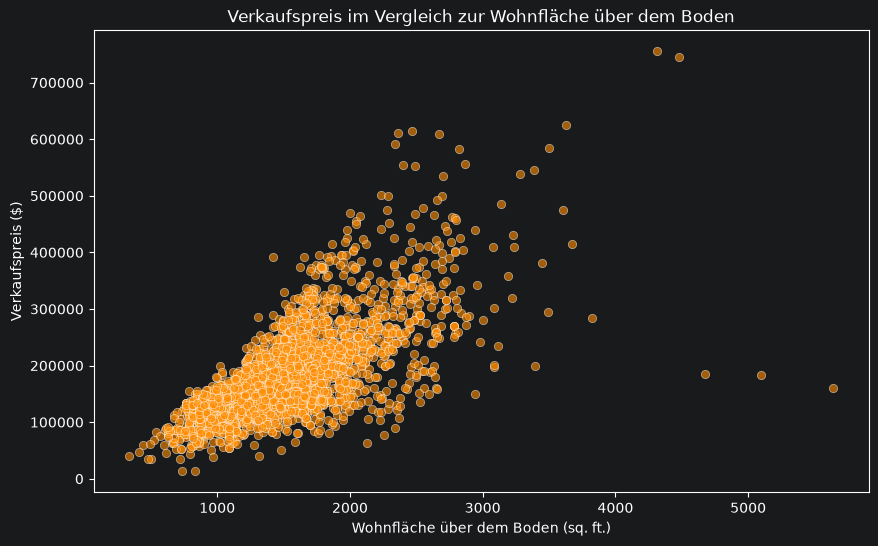

In [9]:
plt.figure(figsize=(10, 6))
# alpha=0.6 makes the dots slightly transparent so we can see where they overlap
sns.scatterplot(x='Gr Liv Area', y='SalePrice', data=train_dataset, alpha=0.6, color='darkorange')
plt.title('Verkaufspreis im Vergleich zur Wohnfläche über dem Boden')
plt.xlabel('Wohnfläche über dem Boden (sq. ft.)')
plt.ylabel('Verkaufspreis ($)')
plt.show()

Die Daten zeigen eine starke positive Korrelation zwischen der Wohnfläche eines Hauses über dem Boden und seinem Verkaufspreis. Mit zunehmender Quadratfußzahl steigen die Preise stetig an, doch die Grafik verdeutlicht auch bekannte extreme Ausreißer innerhalb des Ames-Datensatzes – insbesondere riesige Häuser (über 4.000 Quadratfuß), die zu ungewöhnlich niedrigen Preisen verkauft wurden, oft aufgrund ihres schlechten Zustands oder atypischer Bebauungsvorschriften.

In [10]:
# Filter out the massive outliers
train_dataset = train_dataset[train_dataset['Gr Liv Area'] < 4000]

#### Heatmap
Eine Heatmap wurde verwendet, um die Korrelationsmatrix der Variablen farblich zu kodieren. Starke positive oder negative Zusammenhänge zwischen verschiedenen Merkmalen lassen sich so durch die jeweilige Farbintensität schnell identifizieren.

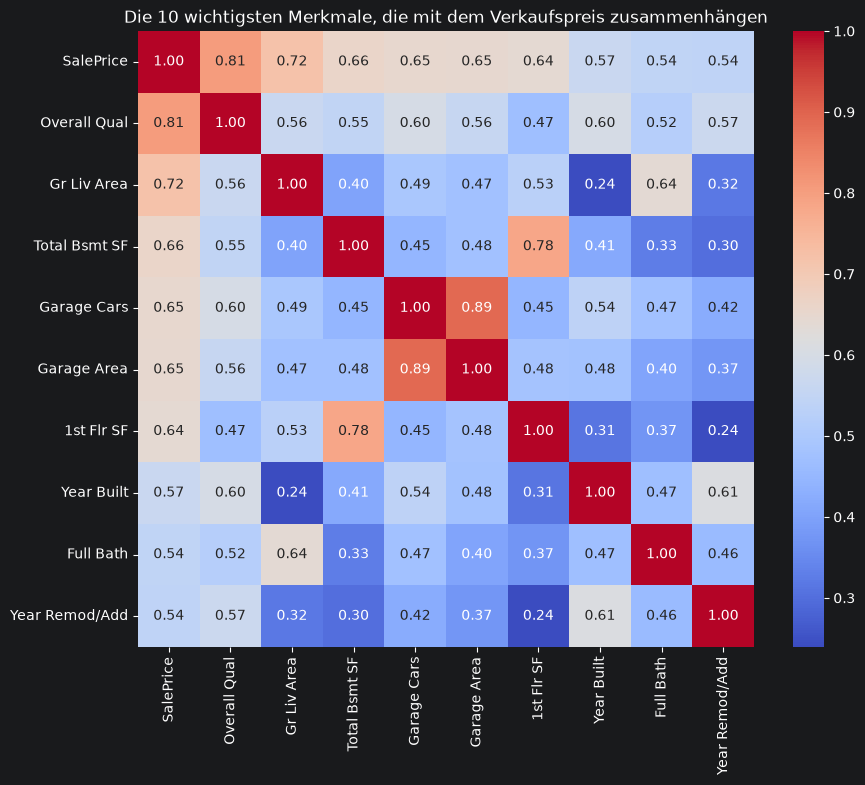

In [11]:
plt.figure(figsize=(10, 8))

numeric_data = train_dataset.select_dtypes(include=['int64', 'float64'])

corr_matrix = numeric_data.corr()

top_corr_cols = corr_matrix.nlargest(10, 'SalePrice')['SalePrice'].index

top_corr_matrix = numeric_data[top_corr_cols].corr()
sns.heatmap(top_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Die 10 wichtigsten Merkmale, die mit dem Verkaufspreis zusammenhängen')
plt.show()

Die Heatmap zeigt, dass „Overall Qual“ (Korrelation ~0,8) und „Gr Liv Area“ (Korrelation ~0,7) die stärksten linearen Prädiktoren für den Verkaufspreis sind. Sie macht zudem eine erhebliche Multikollinearität zwischen den Prädiktorvariablen deutlich; so korreliert beispielsweise „Garage Cars“ nahezu perfekt mit „Garage Area“, und „Total Bsmt SF“ korreliert stark mit „1st Flr SF“, was bedeutet, dass diese gepaarten Merkmale redundante Informationen liefern und bestimmte Vorhersagemodelle verzerren könnten, wenn dies nicht berücksichtigt wird.

#### Lineare Regression
Ein Streudiagramm wurde um eine Regressionsgerade ergänzt, um den linearen Trend zwischen einer unabhängigen und einer abhängigen Variable zu modellieren. Die Gerade veranschaulicht die rechnerisch bestmögliche Anpassung an die Datenpunkte und hilft dabei, die zugrundeliegende Entwicklung abzuschätzen.

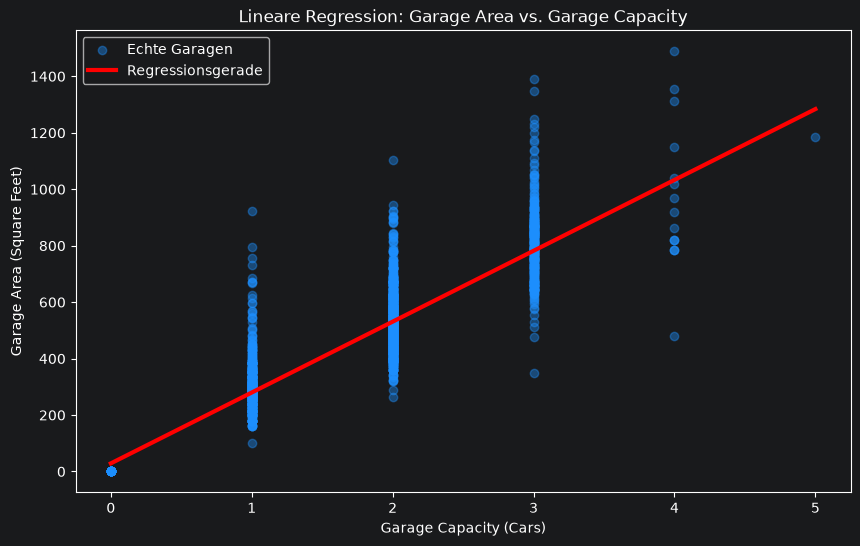

Das Modell sagt voraus, dass eine Garage für zwei Autos ist: 530.86 sq ft
Eine echte Doppelgarage im Datensatz ist: 528.00 sq ft


In [12]:
from sklearn.linear_model import LinearRegression

X = train_dataset[['Garage Cars']].values
y = train_dataset['Garage Area'].values

model = LinearRegression()
model.fit(X, y)

X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model.predict(X_line)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='dodgerblue', alpha=0.4, label='Echte Garagen')
plt.plot(X_line, y_line, color='red', linewidth=3, label='Regressionsgerade')
plt.title('Lineare Regression: Garage Area vs. Garage Capacity')
plt.xlabel('Garage Capacity (Cars)')
plt.ylabel('Garage Area (Square Feet)')
plt.legend()
plt.show()

predicted_area = model.predict([[2]])[0]
print(f"Das Modell sagt voraus, dass eine Garage für zwei Autos ist: {predicted_area:.2f} sq ft")

real_2car_garage = train_dataset[train_dataset['Garage Cars'] == 2]['Garage Area'].iloc[0]
print(f"Eine echte Doppelgarage im Datensatz ist: {real_2car_garage:.2f} sq ft")

Die angepasste Regressionsgerade bestätigt den Aufwärtstrend der Basislinie und quantifiziert den durchschnittlichen Anstieg des Verkaufspreises in Dollar pro zusätzlichem Quadratfuß Wohnfläche. Bei größeren Wohnflächen weichen die Datenpunkte jedoch zunehmend stärker von der Geraden ab (Heteroskedastizität), was zeigt, dass ein einfaches lineares Modell bei größeren Immobilien an Vorhersagegenauigkeit verliert, da dort Luxusausstattung, Lage und Zustand einen wesentlich größeren Einfluss haben als die reine Wohnfläche.

In [13]:
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, f1_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.preprocessing import label_binarize

X = train_dataset.drop(columns=['SalePrice'])
y_continuous = train_dataset['SalePrice']

for col in X.select_dtypes(include=['object', 'string']).columns:
    X[col] = X[col].astype('category')

bins = [0, 100000, 130000, 180000, 250000, 400000, np.inf]
labels = [0, 1, 2, 3, 4, 5]
y = pd.cut(y_continuous, bins=bins, labels=labels, right=False)

sample_weights = compute_sample_weight(class_weight='balanced', y=y)

Die kontinuierliche Variable SalePrice wurde mithilfe von pd.cut in die geforderten sechs Preisklassen diskretisiert. Da in typischen Immobilienmärkten mittlere Preisklassen deutlich stärker vertreten sind als extrem günstige oder teure Häuser, entsteht ein Klassenungleichgewicht (Class Imbalance). Um dies zu beheben, werden im Vorfeld sample_weights berechnet, die dem Modell später beim Training übergeben werden. Dadurch werden Fehlklassifikationen in selteneren Klassen stärker bestraft.

In [14]:
X_train_10, X_test_10, y_train_10, y_test_10 = train_test_split(X, y, test_size=0.1, random_state=42)
X_train_10_strat, X_test_10_strat, y_train_10_strat, y_test_10_strat = train_test_split(X, y, test_size=0.1, stratify=y, random_state=42)

X_train_20, X_test_20, y_train_20, y_test_20 = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_20_strat, X_test_20_strat, y_train_20_strat, y_test_20_strat = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

xgb_base = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    enable_categorical=True,
    random_state=42
)

kf_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kf_10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

cv_5_scores = cross_val_score(xgb_base, X, y, cv=kf_5, scoring='f1_macro')
cv_10_scores = cross_val_score(xgb_base, X, y, cv=kf_10, scoring='f1_macro')

print(f"CV k=5 Macro F1: {cv_5_scores.mean():.4f} (+/- {cv_5_scores.std():.4f})")
print(f"CV k=10 Macro F1: {cv_10_scores.mean():.4f} (+/- {cv_10_scores.std():.4f})")

CV k=5 Macro F1: 0.7340 (+/- 0.0349)
CV k=10 Macro F1: 0.7400 (+/- 0.0289)


Stratifizierung: Ohne Stratifizierung (stratify=None) laufen wir bei kleinen Datensätzen oder starkem Ungleichgewicht Gefahr, dass seltene Klassen (z.B. >= 400.000 USD) im Testset über- oder unterrepräsentiert sind. Die Stratifizierung stellt sicher, dass die Klassenverteilung im Train- und Test-Split identisch zur Gesamtverteilung bleibt. Ein 20%-Split bietet eine robustere Evaluierung, während ein 10%-Split dem Modell mehr Trainingsdaten überlässt.</br> Bias-Variance Tradeoff bei K-Fold: Bei $k=5$ ist das Validierungsset pro Fold größer, was zu einer stabileren Schätzung der Modellgüte (geringere Varianz), aber potenziell einem höheren Bias führt (da jeweils nur 80% der Daten fürs Training genutzt werden). Bei $k=10$ wächst das Trainingsset auf 90% pro Fold, wodurch der Bias der Fehlerschätzung sinkt. Da die Testsets pro Fold aber kleiner werden, kann die Varianz der Metriken zwischen den einzelnen Folds steigen, besonders bei kleinen Minderheitsklassen.

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.71      0.73        48
           1       0.70      0.75      0.73       102
           2       0.81      0.79      0.80       207
           3       0.79      0.80      0.80       137
           4       0.81      0.84      0.82        79
           5       0.86      0.50      0.63        12

    accuracy                           0.78       585
   macro avg       0.79      0.73      0.75       585
weighted avg       0.78      0.78      0.78       585



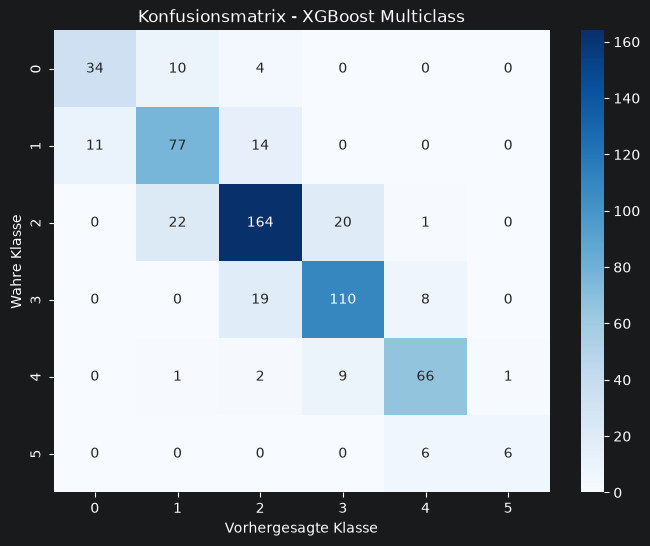

In [15]:
weights_train = compute_sample_weight('balanced', y_train_20_strat)

xgb_base.fit(X_train_20_strat, y_train_20_strat, sample_weight=weights_train)
y_pred = xgb_base.predict(X_test_20_strat)
y_pred_proba = xgb_base.predict_proba(X_test_20_strat)

print("Classification Report:\n", classification_report(y_test_20_strat, y_pred))

plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test_20_strat, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Konfusionsmatrix - XGBoost Multiclass')
plt.ylabel('Wahre Klasse')
plt.xlabel('Vorhergesagte Klasse')
plt.show()

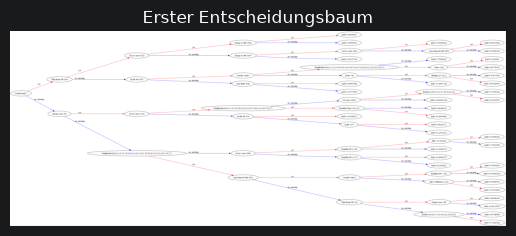

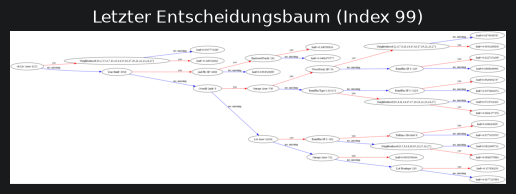

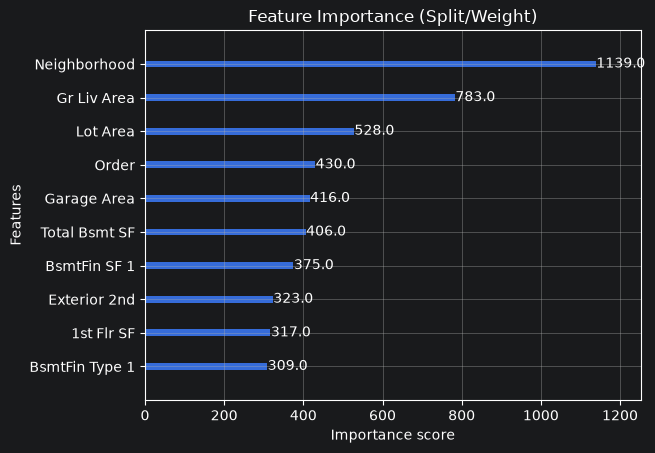

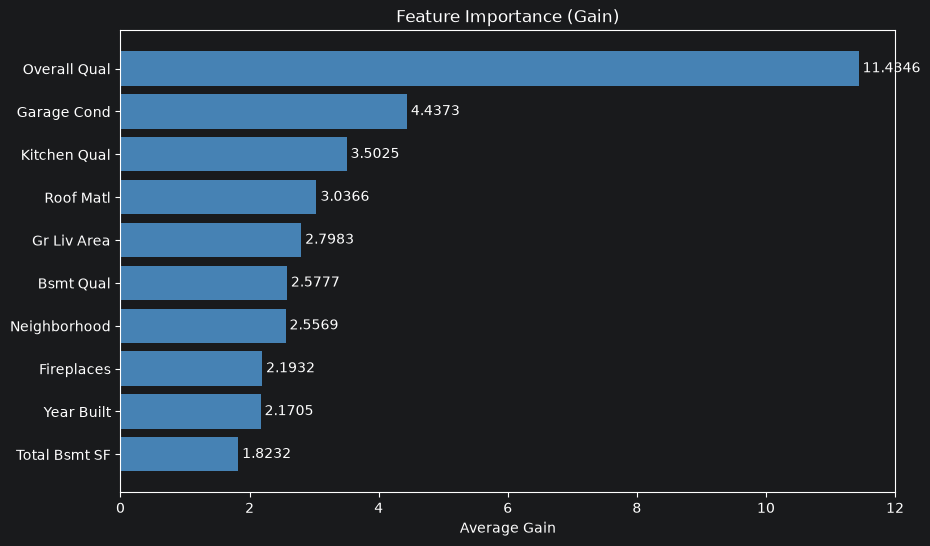

In [23]:
xgb.plot_tree(xgb_base, tree_idx=0, rankdir='LR')
plt.title('Erster Entscheidungsbaum')
plt.show()

last_tree_idx = xgb_base.n_estimators - 1 if xgb_base.n_estimators is not None else 99

xgb.plot_tree(xgb_base, tree_idx=last_tree_idx, rankdir='LR')
plt.title(f'Letzter Entscheidungsbaum (Index {last_tree_idx})')
plt.show()

xgb.plot_importance(xgb_base, importance_type='weight', max_num_features=10, title="Feature Importance (Split/Weight)")
plt.show()

importance_gain = xgb_base.get_booster().get_score(importance_type='gain')
df_imp_gain = pd.DataFrame(list(importance_gain.items()), columns=['Feature', 'Gain'])
df_imp_gain = df_imp_gain.sort_values(by='Gain', ascending=True).tail(10)

plt.figure(figsize=(10, 6))
bars = plt.barh(df_imp_gain['Feature'], df_imp_gain['Gain'], color='steelblue')
plt.title("Feature Importance (Gain)")
plt.xlabel("Average Gain")

for bar in bars:
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height() / 2, f' {width:.4f}', va='center')
plt.show()

Bäume: Der erste Baum repräsentiert die anfängliche, noch grobe Anpassung an die Residuen der Daten, während spätere Bäume sich auf die verbliebenen, schwer zu klassifizierenden Fehler fokussieren.

Gain vs. Split: Split (Weight) zeigt lediglich die reine Häufigkeit, mit der ein Feature in den Bäumen als Entscheidungsknoten herangezogen wird. Kontinuierliche Variablen (wie Wohnfläche) haben hier oft künstlich hohe Werte, da sie viele mögliche Split-Punkte bieten. Gain ist hingegen die wichtigere Metrik: Sie misst den tatsächlichen, durchschnittlichen Beitrag (Informationsgewinn bzw. Fehlerreduktion) eines Features, wenn es für einen Split verwendet wird. Merkmale wie OverallQual haben oft einen hohen Gain, selbst wenn sie weniger oft gesplittet werden.

Klasse 0: Bester PR-Threshold = 0.280, Max F1 = 0.768
Klasse 1: Bester PR-Threshold = 0.556, Max F1 = 0.743
Klasse 2: Bester PR-Threshold = 0.410, Max F1 = 0.817
Klasse 3: Bester PR-Threshold = 0.447, Max F1 = 0.807
Klasse 4: Bester PR-Threshold = 0.659, Max F1 = 0.842
Klasse 5: Bester PR-Threshold = 0.082, Max F1 = 0.800


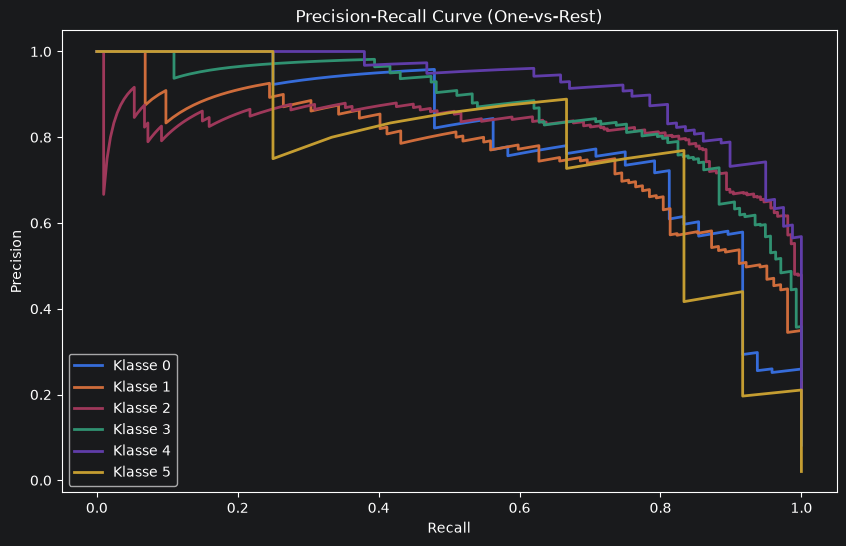

In [24]:
y_test_bin = label_binarize(y_test_20_strat, classes=labels)

best_thresholds = []

plt.figure(figsize=(10, 6))
for i in range(6):
    precision, recall, thresholds = precision_recall_curve(y_test_bin[:, i], y_pred_proba[:, i])
    plt.plot(recall, precision, lw=2, label=f'Klasse {i}')

    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    best_thresholds.append(best_threshold)
    print(f"Klasse {i}: Bester PR-Threshold = {best_threshold:.3f}, Max F1 = {f1_scores[best_idx]:.3f}")

plt.title('Precision-Recall Curve (One-vs-Rest)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()

In [26]:
def objective(trial):
    params = {
        'objective': 'multi:softprob',
        'num_class': 6,
        'device': 'cpu',
        'enable_categorical': True,
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5)
    }

    model = xgb.XGBClassifier(**params, random_state=42)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_train_20_strat, y_train_20_strat, cv=cv, scoring='f1_macro', params={'sample_weight': weights_train})
    return scores.mean()

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler)
study.optimize(objective, n_trials=30)

print("Beste Hyperparameter:", study.best_params)
print("Bester Macro F1-Score:", study.best_value)

optuna.visualization.plot_optimization_history(study).show()
optuna.visualization.plot_param_importances(study).show()

[I 2026-11-02 15:05:06,330] A new study created in memory with name: no-name-38e53a8d-443a-452a-8e90-625fab3d5908
[I 2026-11-02 15:05:18,594] Trial 0 finished with value: 0.7309159475923637 and parameters: {'max_depth': 5, 'learning_rate': 0.22648248189516848, 'n_estimators': 380, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'gamma': 0.7799726016810132}. Best is trial 0 with value: 0.7309159475923637.
[I 2026-11-02 15:05:25,766] Trial 1 finished with value: 0.6987322022539797 and parameters: {'max_depth': 3, 'learning_rate': 0.13983740016490973, 'n_estimators': 321, 'subsample': 0.8832290311184181, 'colsample_bytree': 0.608233797718321, 'gamma': 4.8495492608099715}. Best is trial 0 with value: 0.7309159475923637.
[I 2026-11-02 15:05:37,550] Trial 2 finished with value: 0.712557862822609 and parameters: {'max_depth': 9, 'learning_rate': 0.0033572967053517922, 'n_estimators': 132, 'subsample': 0.6733618039413735, 'colsample_bytree': 0.7216968971838151, 'gamma'

Beste Hyperparameter: {'max_depth': 10, 'learning_rate': 0.13187485350226172, 'n_estimators': 53, 'subsample': 0.6609079086683075, 'colsample_bytree': 0.6278345741902283, 'gamma': 0.4707107273372477}
Bester Macro F1-Score: 0.7455686598627732


Der Tree-structured Parzen Estimator (TPESampler) ist ein Bayes'scher Optimierungsalgorithmus, der nicht blind rät (wie Random Search), sondern aus den bisherigen Evaluierungen lernt. Er modelliert die Wahrscheinlichkeit von Parametern im Verhältnis zur Performance und tastet gezielt den Suchraum ab, in dem höhere Macro-F1-Werte zu erwarten sind. Durch Anpassungen wie max_depth (Kontrolle der Modellkomplexität) und gamma (Mindest-Loss-Reduktion für einen Split) regulieren wir das Overfitting, was auf dem Trainingsdatensatz in den Plots zur Parameter-Importance deutlich sichtbar wird.